In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

url = "https://books.toscrape.com/catalogue/category/books/travel_2/index.html"
rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

response = requests.get(url)
response.encoding = "utf-8"
soup = BeautifulSoup(response.text, "html.parser")

category = soup.find("h1").text.strip()

books = []
for card in soup.find_all("article", class_="product_pod"):
    rating_word = card.find("p", class_="star-rating")["class"][1]
    books.append({
        "Category": category,
        "Title": card.h3.a["title"],
        "Price": float(card.find("p", class_="price_color").text.replace("£", "").replace("Â", "")),
        "Rating": rating_map[rating_word],
        "Availability": card.find("p", class_="availability").text.strip(),
    })

df = pd.DataFrame(books)
print(len(df))
print(df.head())

11
  Category                                              Title  Price  Rating  \
0   Travel                            It's Only the Himalayas  45.17       2   
1   Travel  Full Moon over Noah’s Ark: An Odyssey to Mount...  49.43       4   
2   Travel  See America: A Celebration of Our National Par...  48.87       3   
3   Travel  Vagabonding: An Uncommon Guide to the Art of L...  36.94       2   
4   Travel                               Under the Tuscan Sun  37.33       3   

  Availability  
0     In stock  
1     In stock  
2     In stock  
3     In stock  
4     In stock  


In [3]:
import time
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin
import pandas as pd

HOME = "https://books.toscrape.com/index.html"
rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}


def get_soup(url):
    response = requests.get(url, timeout=15)
    response.encoding = "utf-8"
    return BeautifulSoup(response.text, "html.parser")


def scrape_category(category_url):
    """Scrape every page of one genre, following the 'next' button."""
    books = []
    url = category_url
    while url:
        soup = get_soup(url)
        category = soup.find("h1").text.strip()

        for card in soup.find_all("article", class_="product_pod"):
            rating_word = card.find("p", class_="star-rating")["class"][1]
            books.append({
                "Category": category,
                "Title": card.h3.a["title"],
                "Price": float(card.find("p", class_="price_color").text.replace("£", "").replace("Â", "")),
                "Rating": rating_map[rating_word],
                "Availability": card.find("p", class_="availability").text.strip(),
                "URL": urljoin(url, card.h3.a["href"]),
            })

        next_btn = soup.find("li", class_="next")
        url = urljoin(url, next_btn.a["href"]) if next_btn else None
        time.sleep(0.3)
    return books



home_soup = get_soup(HOME)
genre_links = home_soup.select("div.side_categories ul ul a")
print("Genres found:", len(genre_links))

all_books = []
for link in genre_links:
    genre_url = urljoin(HOME, link["href"])
    genre_books = scrape_category(genre_url)
    print(f"{link.text.strip():<22} {len(genre_books)} books")
    all_books.extend(genre_books)

df = pd.DataFrame(all_books)
df.to_csv("competitor_books.csv", index=False)

print("\nTotal books:", len(df))
print(df.head())
print(df.dtypes)
print("Missing values:", df.isna().sum().sum())

Genres found: 50
Travel                 11 books
Mystery                32 books
Historical Fiction     26 books
Sequential Art         75 books
Classics               19 books
Philosophy             11 books
Romance                35 books
Womens Fiction         17 books
Fiction                65 books
Childrens              29 books
Religion               7 books
Nonfiction             110 books
Music                  13 books
Default                152 books
Science Fiction        16 books
Sports and Games       5 books
Add a comment          67 books
Fantasy                48 books
New Adult              6 books
Young Adult            54 books
Science                14 books
Poetry                 19 books
Paranormal             1 books
Art                    8 books
Psychology             7 books
Autobiography          9 books
Parenting              1 books
Adult Fiction          1 books
Humor                  10 books
Horror                 17 books
History                18 book

In [5]:

print("REQUIRED QUESTIONS")
top = df.loc[df["Price"].idxmax()]
low = df.loc[df["Price"].idxmin()]
print(f"1. Most expensive: {top['Title']} | £{top['Price']:.2f} | {top['Category']}")
print(f"2. Cheapest:       {low['Title']} | £{low['Price']:.2f} | {low['Category']}")
print(f"3. Average price:  £{df['Price'].mean():.2f}")
print(f"4. 5-star books:   {(df['Rating'] == 5).sum()}")
in_stock_pct = df["Availability"].str.contains("In stock", case=False).mean() * 100
print(f"5. In stock:       {in_stock_pct:.1f}%")

print("6. Top 5 highest-rated (ties broken by lower price):")
print(df.sort_values(["Rating", "Price"], ascending=[False, True])
        .head(5)[["Title", "Category", "Rating", "Price"]].to_string(index=False))

five = df[df["Rating"] == 5]
c5 = five.loc[five["Price"].idxmin()]
print(f"7. Cheapest 5-star: {c5['Title']} | £{c5['Price']:.2f} | {c5['Category']}")

print("\nBooks per rating level:")
print(df["Rating"].value_counts().sort_index())

real = df[~df["Category"].isin(["Default", "Add a comment"])]
print(f"\nReal-genre books: {len(real)} (removed {len(df) - len(real)} placeholder-labelled)")

genre = real.groupby("Category").agg(
    Books=("Title", "count"),
    AvgPrice=("Price", "mean"),
    AvgRating=("Rating", "mean"),
    Pct5Star=("Rating", lambda r: (r == 5).mean() * 100),
).round(2)
genre["StarsPerPound"] = (genre["AvgRating"] / genre["AvgPrice"]).round(3)

# Only genres with 10+ books, so tiny genres (1 book) don't distort the ranking
big = genre[genre["Books"] >= 10]

print("\nTop 5 genres by average rating (10+ books):")
print(big.sort_values("AvgRating", ascending=False).head(5))

print("\nTop 5 genres by value, stars per pound (10+ books):")
print(big.sort_values("StarsPerPound", ascending=False).head(5))

print("\nGenres with the lowest average price (10+ books):")
print(big.sort_values("AvgPrice").head(5))

REQUIRED QUESTIONS
1. Most expensive: The Perfect Play (Play by Play #1) | £59.99 | Romance
2. Cheapest:       An Abundance of Katherines | £10.00 | Young Adult
3. Average price:  £35.07
4. 5-star books:   196
5. In stock:       100.0%
6. Top 5 highest-rated (ties broken by lower price):
                                                     Title       Category  Rating  Price
                                An Abundance of Katherines    Young Adult       5  10.00
                                      Greek Mythic History        Default       5  10.23
The Power Greens Cookbook: 140 Delicious Superfood Recipes Food and Drink       5  11.05
                                        Dear Mr. Knightley        Fiction       5  11.21
                                       The Darkest Corners    Young Adult       5  11.33
7. Cheapest 5-star: An Abundance of Katherines | £10.00 | Young Adult

Books per rating level:
Rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

Rea

In [6]:
import numpy as np

def best_basket(data, budget=100.0):
    """Exact 0/1 knapsack: maximise total stars with total cost <= budget."""
    costs = (data["Price"] * 100).round().astype(int).tolist()
    vals = data["Rating"].tolist()
    cap = int(round(budget * 100))
    n = len(costs)

    dp = np.zeros(cap + 1, dtype=np.int32)
    keep = np.zeros((n, cap + 1), dtype=bool)
    for i in range(n):
        c, v = costs[i], vals[i]
        if c > cap:
            continue
        cand = dp[:cap + 1 - c] + v
        better = cand > dp[c:]
        keep[i, c:] = better
        dp[c:] = np.where(better, cand, dp[c:])

    chosen, w = [], cap
    for i in range(n - 1, -1, -1):
        if keep[i, w]:
            chosen.append(i)
            w -= costs[i]
    return data.iloc[chosen[::-1]]


basket = best_basket(df, 100.0)

print("CEO £100 CHALLENGE (optimal)")
print(basket[["Title", "Category", "Price", "Rating"]].to_string(index=False))
print(f"\nBooks bought: {len(basket)}")
print(f"Total cost:   £{basket['Price'].sum():.2f}")
print(f"Total rating: {basket['Rating'].sum()} stars")
print("\nGenres in the basket:")
print(basket["Category"].value_counts())


g = df.assign(Value=df["Rating"] / df["Price"]).sort_values("Value", ascending=False)
spent, stars, picked = 0.0, 0, 0
for _, row in g.iterrows():
    if spent + row["Price"] <= 100:
        spent += row["Price"]
        stars += row["Rating"]
        picked += 1
print(f"\nGreedy approach: {picked} books, £{spent:.2f}, {stars} stars")

CEO £100 CHALLENGE (optimal)
                                                                                  Title       Category  Price  Rating
                                                                      The Girl You Lost        Mystery  12.29       5
                          Superman Vol. 1: Before Truth (Superman by Gene Luen Yang #1) Sequential Art  11.89       5
                                               Fruits Basket, Vol. 2 (Fruits Basket #2) Sequential Art  11.64       5
                                                                     Dear Mr. Knightley        Fiction  11.21       5
                                                                   Greek Mythic History        Default  10.23       5
                                                                    The Darkest Corners    Young Adult  11.33       5
                                                             An Abundance of Katherines    Young Adult  10.00       5
                           

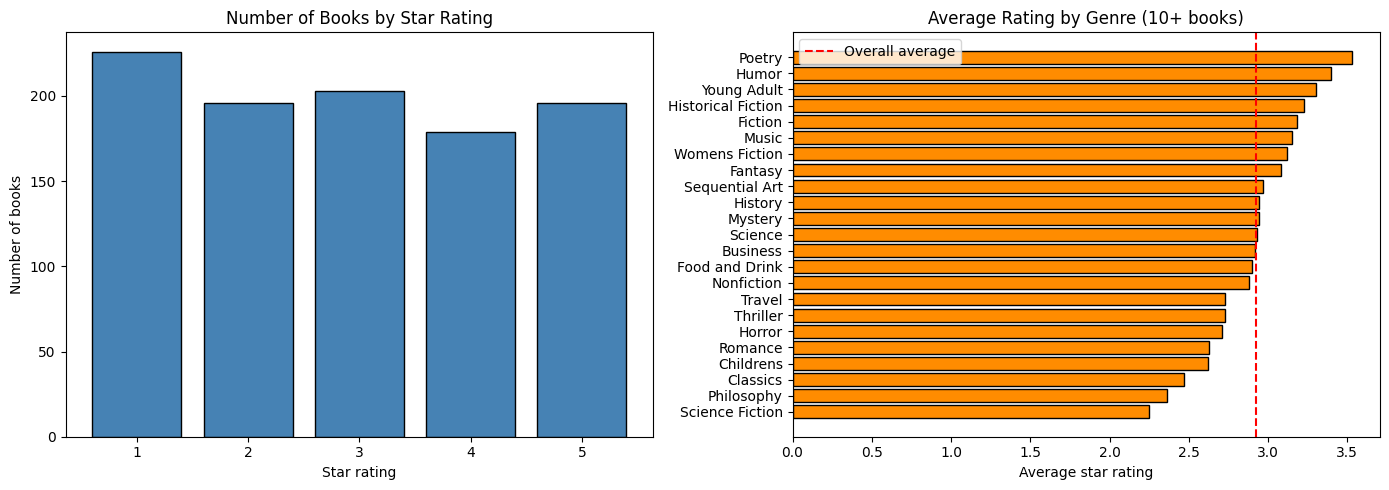

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: books per star rating (Bonus 4)
counts = df["Rating"].value_counts().sort_index()
axes[0].bar(counts.index.astype(str), counts.values, color="steelblue", edgecolor="black")
axes[0].set_title("Number of Books by Star Rating")
axes[0].set_xlabel("Star rating")
axes[0].set_ylabel("Number of books")

# Chart 2: average rating by genre (genres with 10+ books, real genres only)
plot_data = big.sort_values("AvgRating")
axes[1].barh(plot_data.index, plot_data["AvgRating"], color="darkorange", edgecolor="black")
axes[1].axvline(df["Rating"].mean(), color="red", linestyle="--", label="Overall average")
axes[1].set_title("Average Rating by Genre (10+ books)")
axes[1].set_xlabel("Average star rating")
axes[1].legend()

plt.tight_layout()
plt.savefig("bookstore_charts.png", dpi=150)
plt.show()